# 06 — Sellers and products

**Questions**
1. How concentrated is revenue among sellers (Pareto)? Who are the best and worst sellers?
2. Which categories drive revenue, which carry heavy freight, and which disappoint customers?
3. Which categories have the highest cancellation and late-delivery rates?
4. Can we build a single **seller health scorecard** that ops can act on?

**Grain:** item level (`order_items`) for revenue and freight; order level for reviews, lateness and cancellation (so multi-item orders are not double counted).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from viz_style import *

P = Path("../data/processed")
orders  = pd.read_csv(P / "orders.csv", parse_dates=["order_purchase_timestamp"])
items   = pd.read_csv(P / "order_items.csv")
prods   = pd.read_csv(P / "products.csv")
sellers = pd.read_csv(P / "sellers.csv")
reviews = pd.read_csv(P / "reviews.csv")

it = (items.merge(prods[["product_id", "product_category_name_english"]].rename(columns={"product_category_name_english": "category"}), on="product_id")
           .merge(orders[["order_id", "order_status", "is_delivered", "is_late", "delivery_days", "order_purchase_timestamp"]], on="order_id")
           .merge(reviews[["order_id", "review_score"]], on="order_id", how="left")
           .merge(sellers[["seller_id", "seller_state"]], on="seller_id"))
deliv = it[it.is_delivered]
print(f"{len(it):,} items in all statuses; {len(deliv):,} delivered items from {deliv.seller_id.nunique():,} sellers")

112,650 items in all statuses; 110,197 delivered items from 2,970 sellers


## 1. Seller Pareto

In [2]:
srev = deliv.groupby("seller_id").price.sum().sort_values(ascending=False)
cum = srev.cumsum() / srev.sum()
n = len(srev)
n80 = int((cum < 0.80).sum() + 1)
n50 = int((cum < 0.50).sum() + 1)
print(f"{n:,} active sellers. Top {n50:,} ({100*n50/n:.1f}%) make 50% of revenue; top {n80:,} ({100*n80/n:.1f}%) make 80%.")
print(f"Top 20 sellers alone: {100*cum.iloc[19]:.1f}% of revenue. Bottom half of sellers: {100*(1-cum.iloc[n//2-1]):.1f}% of revenue.")

2,970 active sellers. Top 127 (4.3%) make 50% of revenue; top 533 (17.9%) make 80%.
Top 20 sellers alone: 21.3% of revenue. Bottom half of sellers: 3.3% of revenue.


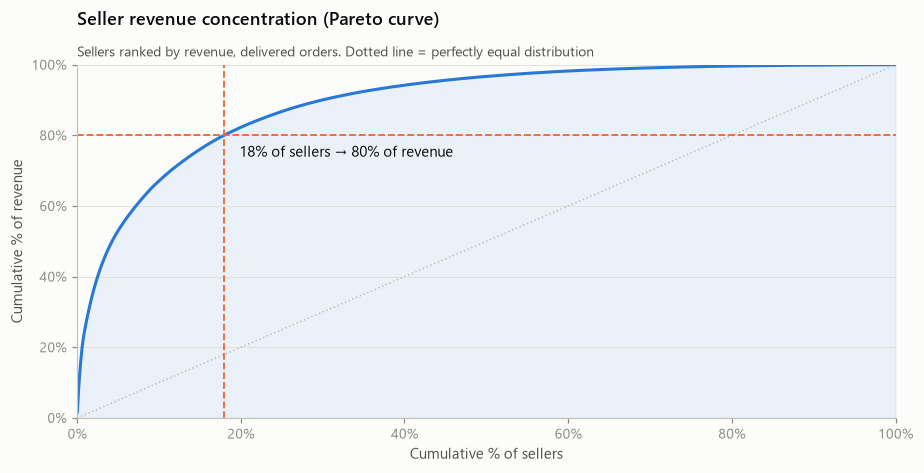

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
x = np.arange(1, n + 1) / n * 100
ax.plot(x, cum.values * 100, color=BLUE)
ax.fill_between(x, cum.values * 100, color=BLUE, alpha=0.08)
ax.plot([0, 100], [0, 100], color=AXIS, lw=1, ls=":")
ax.axvline(100*n80/n, color=ORANGE, lw=1.2, ls="--"); ax.axhline(80, color=ORANGE, lw=1.2, ls="--")
ax.annotate(f"{100*n80/n:.0f}% of sellers → 80% of revenue", (100*n80/n, 80), textcoords="offset points", xytext=(10, -14), fontsize=9.5, color=INK)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter()); ax.yaxis.set_major_formatter(PercentFormatter())
finish(ax, "Seller revenue concentration (Pareto curve)", "Sellers ranked by revenue, delivered orders. Dotted line = perfectly equal distribution",
       xlabel="Cumulative % of sellers", ylabel="Cumulative % of revenue")
plt.tight_layout(); save(fig, "06_seller_pareto"); plt.show()

## 2. Seller health scorecard

One row per seller with volume, revenue, on-time %, average review and a composite health score. Sellers with fewer than 30 delivered orders are kept but flagged `low_volume` — their rates are noisy.

In [4]:
order_level = (deliv.drop_duplicates(["order_id", "seller_id"])
                    .groupby("seller_id")
                    .agg(orders=("order_id", "nunique"), on_time_pct=("is_late", lambda s: 100 * (1 - s.dropna().mean()) if s.notna().any() else np.nan),
                         avg_review=("review_score", "mean"), avg_delivery_days=("delivery_days", "mean"),
                         pct_1_2_star=("review_score", lambda s: 100 * (s.dropna() <= 2).mean() if s.notna().any() else np.nan),
                         first_sale=("order_purchase_timestamp", "min"), last_sale=("order_purchase_timestamp", "max")))
item_level = deliv.groupby("seller_id").agg(items=("order_id", "size"), revenue=("price", "sum"), freight=("freight_value", "sum"),
                                            n_categories=("category", "nunique"), state=("seller_state", "first"))
cancel = (it.drop_duplicates(["order_id", "seller_id"]).groupby("seller_id").order_status
            .apply(lambda s: 100 * s.isin(["canceled", "unavailable"]).mean()).rename("cancel_pct"))

score = item_level.join(order_level).join(cancel)
score["revenue_rank"] = score.revenue.rank(ascending=False, method="min").astype(int)
score["revenue_share_pct"] = 100 * score.revenue / score.revenue.sum()
score["low_volume"] = score.orders < 30
score["first_sale"], score["last_sale"] = score.first_sale.dt.date, score.last_sale.dt.date

# Composite health: equal-weight z-ish scores on on-time, review, cancel (lower better), scaled 0-100 among sellers with >= 30 orders
elig = score[~score.low_volume]
def scale(s, invert=False):
    r = (s - s.min()) / (s.max() - s.min()); return 100 * (1 - r if invert else r)
score.loc[elig.index, "health_score"] = (scale(elig.on_time_pct) + scale(elig.avg_review) + scale(elig.cancel_pct, invert=True)) / 3
score = score.sort_values("revenue", ascending=False)
score.round(2).head(15)

,items,revenue,freight,n_categories,state,orders,on_time_pct,avg_review,avg_delivery_days,pct_1_2_star,first_sale,last_sale,cancel_pct,revenue_rank,revenue_share_pct,low_volume,health_score
seller_id,,,,,,,,,,,,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,1148,226987.93,20019.13,10,SP,1124,89.50,4.15,15.06,13.08,2017-03-14,2018-08-24,0.09,1,1.72,False,77.98
53243585a1d6dc2643021fd1853d8905,400,217940.44,12856.58,2,BA,348,96.55,4.19,13.43,10.40,2017-08-28,2018-08-21,0.00,2,1.65,False,86.16
4a3ca9315b744ce9f8e9374361493884,1949,196882.12,34338.31,7,SP,1772,90.29,3.85,14.49,18.48,2017-01-08,2018-08-27,0.11,3,1.49,False,74.89
fa1c13f2614d7b5c4749cbc52fecda94,579,190917.14,9916.36,5,SP,578,90.83,4.37,13.35,9.58,2017-01-07,2018-08-29,0.17,4,1.44,False,81.80
7c67e1448b00f6e969d365cea6b010ab,1355,186570.05,51236.64,6,SP,973,90.85,3.50,22.34,25.44,2017-01-26,2018-08-07,0.00,5,1.41,False,71.44
7e93a43ef30c4f03f38b393420bc753a,322,165981.49,5992.06,7,SP,319,95.30,4.36,11.31,8.18,2016-10-08,2018-07-13,1.19,6,1.26,False,81.51
da8622b14eb17ae2831f4ac5b9dab84a,1548,159816.87,24889.91,4,SP,1311,93.36,4.18,11.19,11.72,2017-02-05,2018-08-28,0.00,7,1.21,False,82.73
7a67c85e85bb2ce8582c35f2203ad736,1155,139658.69,20619.83,2,SP,1145,94.76,4.28,11.20,9.85,2017-01-27,2018-08-21,0.09,8,1.06,False,84.98
1025f0e2d44d7041d6cf58b6550e0bfa,1420,138208.56,33716.40,4,SP,910,92.09,4.01,12.39,16.96,2017-07-09,2018-08-26,0.00,9,1.05,False,79.20


In [5]:
# Top and bottom 10 by review among sellers with >= 30 orders
elig = score[~score.low_volume]
print("TOP 10 sellers by average review (>=30 orders)")
display(elig.nlargest(10, "avg_review")[["state", "orders", "revenue", "on_time_pct", "avg_review", "health_score"]].round(2))
print("BOTTOM 10 sellers by average review (>=30 orders)")
display(elig.nsmallest(10, "avg_review")[["state", "orders", "revenue", "on_time_pct", "avg_review", "cancel_pct", "health_score"]].round(2))

TOP 10 sellers by average review (>=30 orders)


,state,orders,revenue,on_time_pct,avg_review,health_score
seller_id,,,,,,
48efc9d94a9834137efd9ea76b065a38,PR,33,345.60,100.00,5.00,100.00
02f5837340d7eb4f653d676c7256523a,PR,30,3883.05,96.67,4.83,94.46
d13e50eaa47b4cbe9eb81465865d8cfc,SP,66,7073.05,90.91,4.82,88.37
b410bdd36d5db7a65dcd42b7ead933b8,GO,42,7368.90,100.00,4.81,97.56
83e197e95a1bbabc8c75e883ed016c47,RJ,46,6574.19,97.83,4.80,95.27
d9bd94811c3338dceb4181f3dbc0c73e,SP,54,6911.02,94.44,4.80,91.71
5a93f3ab0ef4c84ed5e1b5dbf23978bc,SP,38,2299.28,97.37,4.79,94.61
d566c37fa119d5e66c4e9052e83ee4ea,SP,65,5145.70,100.00,4.69,96.01
18e694e0e48ed6f7aa3f24aade5fd697,SP,31,701.54,96.77,4.68,92.57


BOTTOM 10 sellers by average review (>=30 orders)


,state,orders,revenue,on_time_pct,avg_review,cancel_pct,health_score
seller_id,,,,,,,
1ca7077d890b907f89be8c954a02686a,SP,108,12474.64,83.33,2.39,0.00,49.60
2eb70248d66e0e3ef83659f71b244378,SP,187,38990.72,88.77,2.79,0.00,60.30
972d0f9cf61b499a4812cf0bfa3ad3c4,SC,81,7910.42,88.89,3.03,0.00,63.38
a49928bcdf77c55c6d6e05e09a9b4ca5,SP,96,8646.90,78.12,3.03,0.00,52.44
54965bbe3e4f07ae045b90b0b8541f52,PR,73,10351.70,69.86,3.14,0.00,45.43
2a1348e9addc1af5aaa619b1a3679d6b,MG,48,2697.40,72.92,3.17,1.92,39.91
bbad7e518d7af88a0897397ffdca1979,SP,68,4426.32,83.82,3.18,0.00,60.16
602044f2c16190c2c6e45eb35c2e21cb,SP,48,3559.17,83.33,3.23,0.00,60.36
5058e8c1e82653974541e83690655b4a,SP,62,9812.83,88.71,3.25,0.00,66.02


In [6]:
# Big sellers with poor health = highest-leverage fixes
risk = elig[(elig.revenue_rank <= 100) & (elig.health_score < elig.health_score.quantile(0.25))]
print(f"{len(risk)} of the top-100 sellers by revenue sit in the bottom quartile of health; they carry {risk.revenue_share_pct.sum():.1f}% of revenue.")
risk[["state", "orders", "revenue", "revenue_rank", "on_time_pct", "avg_review", "cancel_pct", "health_score"]].round(2)

20 of the top-100 sellers by revenue sit in the bottom quartile of health; they carry 8.6% of revenue.


,state,orders,revenue,revenue_rank,on_time_pct,avg_review,cancel_pct,health_score
seller_id,,,,,,,,
4a3ca9315b744ce9f8e9374361493884,SP,1772,196882.12,3,90.29,3.85,0.11,74.89
7c67e1448b00f6e969d365cea6b010ab,SP,973,186570.05,5,90.85,3.50,0.00,71.44
7d13fca15225358621be4086e1eb0964,SP,558,112436.18,14,88.53,4.04,0.00,76.00
f7ba60f8c3f99e7ee4042fdef03b70c4,SP,218,68070.00,22,86.24,4.22,0.00,75.94
7ddcbb64b5bc1ef36ca8c151f6ec77df,SP,325,54435.66,31,91.69,4.03,0.60,76.27
f5a590cf36251cf1162ea35bef76fe84,SP,113,51232.78,35,92.92,4.27,2.56,71.51
8160255418d5aaa7dbdc9f4c64ebda44,SP,380,46368.39,41,86.32,3.95,0.00,72.63
712e6ed8aa4aa1fa65dab41fed5737e4,SC,77,39385.00,58,79.22,3.39,0.00,58.20
634964b17796e64304cadf1ad3050fb7,RJ,265,39114.10,59,90.57,4.06,0.37,76.54


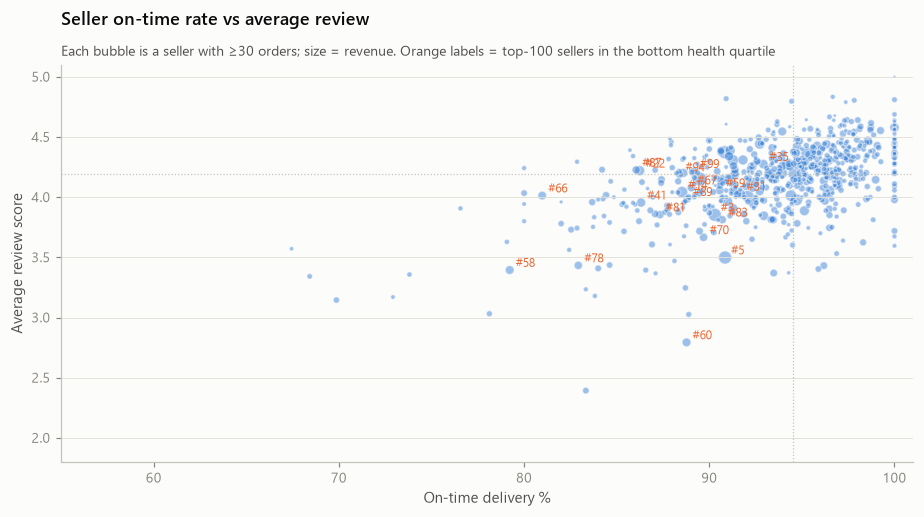

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
e = elig
ax.scatter(e.on_time_pct, e.avg_review, s=np.sqrt(e.revenue) / 6, color=BLUE, alpha=0.45, edgecolor=SURFACE, linewidth=0.8)
for sid, r in risk.iterrows():
    ax.annotate(f"#{r.revenue_rank}", (r.on_time_pct, r.avg_review), fontsize=8, color=ORANGE, textcoords="offset points", xytext=(4, 2))
ax.axhline(e.avg_review.median(), color=AXIS, lw=0.8, ls=":"); ax.axvline(e.on_time_pct.median(), color=AXIS, lw=0.8, ls=":")
ax.set_xlim(55, 101); ax.set_ylim(1.8, 5.1)
finish(ax, "Seller on-time rate vs average review", "Each bubble is a seller with ≥30 orders; size = revenue. Orange labels = top-100 sellers in the bottom health quartile",
       xlabel="On-time delivery %", ylabel="Average review score")
plt.tight_layout(); save(fig, "06_seller_health_scatter"); plt.show()

## 3. Category economics

Revenue, average price, freight-to-price ratio (a margin proxy: heavy, cheap items are expensive to ship relative to their value) and review score.

In [8]:
cat_items = deliv.groupby("category").agg(items=("order_id", "size"), orders=("order_id", "nunique"), revenue=("price", "sum"),
                                          avg_price=("price", "mean"), freight=("freight_value", "sum"), sellers=("seller_id", "nunique"))
cat_items["freight_to_price_pct"] = 100 * cat_items.freight / cat_items.revenue
cat_items["revenue_share_pct"]    = 100 * cat_items.revenue / cat_items.revenue.sum()

cat_orders = (deliv.drop_duplicates(["order_id", "category"]).groupby("category")
                   .agg(avg_review=("review_score", "mean"), late_pct=("is_late", lambda s: 100 * s.dropna().mean())))
cat_all = (it.drop_duplicates(["order_id", "category"]).groupby("category").order_status
             .apply(lambda s: 100 * s.isin(["canceled", "unavailable"]).mean()).rename("cancel_pct"))
cat = cat_items.join(cat_orders).join(cat_all).sort_values("revenue", ascending=False)
cat.round(2).head(15)

,items,orders,revenue,avg_price,freight,sellers,freight_to_price_pct,revenue_share_pct,avg_review,late_pct,cancel_pct
category,,,,,,,,,,,
health_beauty,9465,8647,1233131.72,130.28,178957.81,479,14.51,9.33,4.23,7.51,0.41
watches_gifts,5859,5495,1166176.98,199.04,98156.14,95,8.42,8.82,4.12,7.39,0.36
bed_bath_table,10953,9272,1023434.76,93.44,201774.50,189,19.72,7.74,4.00,7.43,0.19
sports_leisure,8431,7530,954852.55,113.25,163404.36,466,17.11,7.22,4.23,6.57,0.61
computers_accessories,7644,6530,888724.61,116.26,143999.16,279,16.20,6.72,4.08,6.39,0.52
furniture_decor,8160,6307,711927.69,87.25,168402.23,352,23.65,5.38,4.06,7.12,0.37
housewares,6795,5743,615628.69,90.60,142763.56,452,23.19,4.66,4.19,5.36,0.63
cool_stuff,3718,3559,610204.10,164.12,81476.79,259,13.35,4.62,4.22,5.90,0.44
auto,4140,3810,578966.65,139.85,90488.10,371,15.63,4.38,4.15,7.30,0.64


In [9]:
big = cat[cat.orders >= 500]
print("Highest freight burden (>=500 orders):"); display(big.nlargest(8, "freight_to_price_pct")[["orders", "avg_price", "freight_to_price_pct", "avg_review"]].round(1))
print("Worst reviewed:"); display(big.nsmallest(8, "avg_review")[["orders", "revenue", "avg_review", "late_pct", "cancel_pct"]].round(2))
print("Highest cancellation / unavailable rate:"); display(big.nlargest(8, "cancel_pct")[["orders", "revenue", "cancel_pct", "late_pct"]].round(2))
print("Highest late-delivery rate:"); display(big.nlargest(8, "late_pct")[["orders", "revenue", "late_pct", "avg_review"]].round(2))

Highest freight burden (>=500 orders):


,orders,avg_price,freight_to_price_pct,avg_review
category,,,,
electronics,2517,56.8,29.5,4.1
office_furniture,1254,160.8,25.0,3.6
furniture_decor,6307,87.2,23.7,4.1
housewares,5743,90.6,23.2,4.2
telephony,4093,69.9,22.4,4.1
luggage_accessories,1019,128.8,21.7,4.4
garden_tools,3448,110.2,20.5,4.2
fashion_bags_accessories,1820,75.2,20.5,4.2


Worst reviewed:


,orders,revenue,avg_review,late_pct,cancel_pct
category,,,,,
office_furniture,1254,268154.31,3.64,8.05,0.08
bed_bath_table,9272,1023434.76,4.00,7.43,0.19
unknown,1392,170726.63,4.01,7.26,0.96
telephony,4093,309860.23,4.05,7.11,0.38
furniture_decor,6307,711927.69,4.06,7.12,0.37
computers_accessories,6530,888724.61,4.08,6.39,0.52
baby,2809,400421.84,4.10,8.05,0.59
watches_gifts,5495,1166176.98,4.12,7.39,0.36


Highest cancellation / unavailable rate:


,orders,revenue,cancel_pct,late_pct
category,,,,
musical_instruments,611,184315.74,1.27,7.53
small_appliances,609,182754.12,1.27,4.76
unknown,1392,170726.63,0.96,7.26
toys,3804,471286.48,0.80,6.39
consoles_games,1018,148003.37,0.75,6.09
auto,3810,578966.65,0.64,7.30
housewares,5743,615628.69,0.63,5.36
sports_leisure,7530,954852.55,0.61,6.57


Highest late-delivery rate:


,orders,revenue,late_pct,avg_review
category,,,,
office_furniture,1254,268154.31,8.05,3.64
baby,2809,400421.84,8.05,4.10
electronics,2517,155043.93,7.63,4.12
musical_instruments,611,184315.74,7.53,4.23
health_beauty,8647,1233131.72,7.51,4.23
bed_bath_table,9272,1023434.76,7.43,4.00
watches_gifts,5495,1166176.98,7.39,4.12
construction_tools_construction,736,142108.49,7.34,4.13


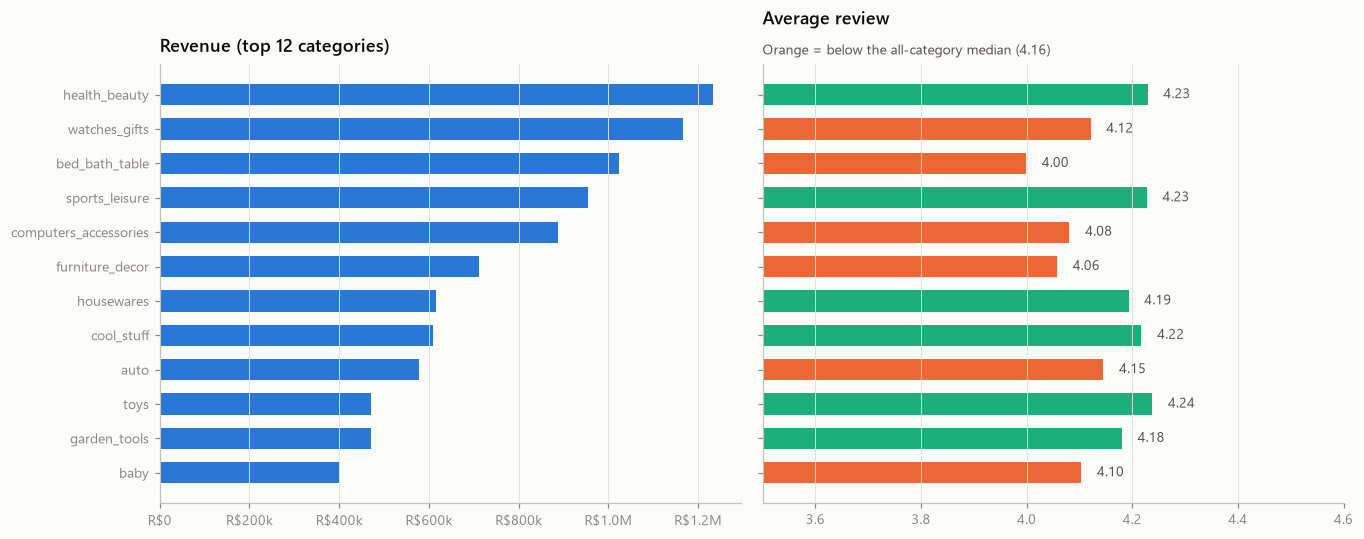

In [10]:
top = cat.head(12)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), sharey=True)
y = np.arange(len(top))[::-1]
axes[0].barh(y, top.revenue, color=BLUE, height=0.62)
axes[0].xaxis.set_major_formatter(FuncFormatter(fmt_brl)); axes[0].grid(axis="y", visible=False); axes[0].grid(axis="x", visible=True)
finish(axes[0], "Revenue (top 12 categories)")
axes[1].barh(y, top.avg_review, color=[ORANGE if v < cat.avg_review.median() else AQUA for v in top.avg_review], height=0.62)
for yi, v in zip(y, top.avg_review): axes[1].text(v + 0.03, yi, f"{v:.2f}", va="center", fontsize=9, color=INK2)
axes[1].set_xlim(3.5, 4.6); axes[1].grid(axis="y", visible=False); axes[1].grid(axis="x", visible=True)
finish(axes[1], "Average review", f"Orange = below the all-category median ({cat.avg_review.median():.2f})")
axes[0].set_yticks(y); axes[0].set_yticklabels(top.index)
plt.tight_layout(); save(fig, "06_category_revenue_review"); plt.show()

In [11]:
score.round(3).to_csv(P / "seller_scorecard.csv")
cat.round(3).to_csv(P / "category_summary.csv")
pd.DataFrame({"cum_sellers_pct": np.arange(1, n + 1) / n * 100, "cum_revenue_pct": cum.values * 100}, index=srev.index).round(3).to_csv(P / "seller_pareto.csv")
print("exported seller_scorecard.csv, category_summary.csv, seller_pareto.csv")

exported seller_scorecard.csv, category_summary.csv, seller_pareto.csv


## So what

- **Revenue is concentrated.** 533 sellers (17.9% of 2,970) generate 80% of revenue; the top 127 (4.3%) make half, and the top 20 alone make 21%. The bottom half of sellers contributes 3.3%. Seller-management effort should go to the ~500 sellers that matter, with a lighter self-serve model for the tail.
- **Twenty large sellers are the weakest link.** 20 of the top-100 sellers by revenue sit in the bottom quartile of health (on-time rates of 79–93%, reviews as low as 2.8) and together carry 8.6% of all revenue. Fixing those 20 accounts moves marketplace KPIs more than onboarding hundreds of small ones.
- **Freight is the hidden margin problem in bulky, low-price categories.** Electronics, office furniture, furniture/decor, housewares and telephony ship at 22–30% of item value; office furniture is also the worst-reviewed category (3.64) with the highest late rate (8.1%). Pricing freight correctly, or regional fulfilment, matters more there than anywhere else.

**Recommendations**
1. **Seller health programme:** monthly scorecard; sellers under a health threshold get a 30-day improvement plan, with top-100 accounts handled first.
2. **Category-specific delivery promises:** add buffer days (or regional stock) for furniture/bulky categories instead of one global promise, because that is where lateness and bad reviews cluster.